<a href="https://colab.research.google.com/github/fboldt/aulas-am-bsi/blob/main/aula17a_PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from sklearn.datasets import load_breast_cancer
import numpy as np
X, y = load_breast_cancer(return_X_y=True)
print(X.shape)
print(np.unique(y))

(569, 30)
[0 1]


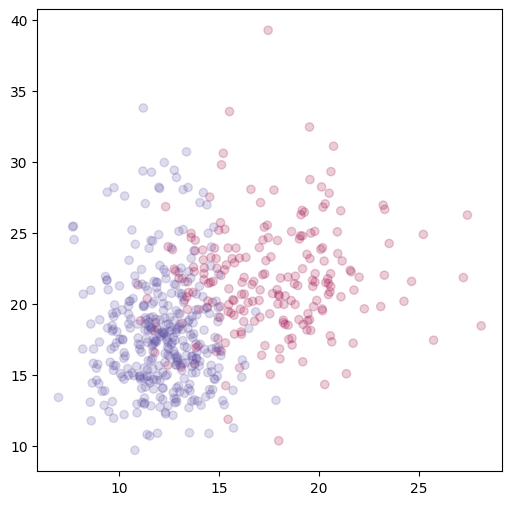

In [6]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6,6))
plt.scatter(X[:,0], X[:,1], c=y, alpha=0.2, cmap="Spectral")
plt.show()

# Principal Component Analisys (PCA)

In [7]:
from sklearn.decomposition import PCA
pca = PCA(n_components=30)
pca.fit(X)
X_pca = pca.transform(X)
print(X_pca.shape)

(569, 30)


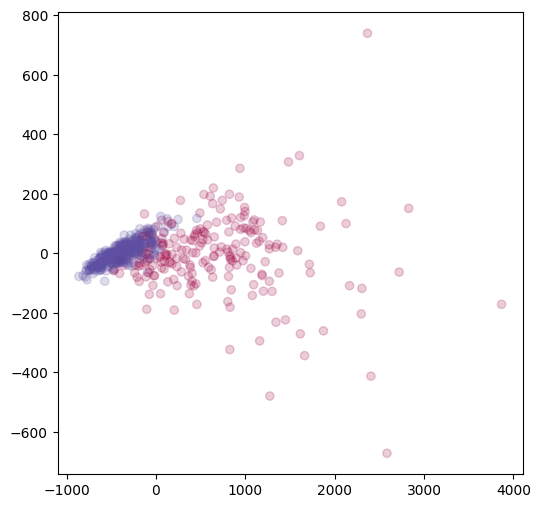

In [8]:
plt.figure(figsize=(6,6))
plt.scatter(X_pca[:,0], X_pca[:,1], c=y, alpha=0.2, cmap="Spectral")
plt.show()

In [9]:
print(pca.explained_variance_ratio_)

[9.82044672e-01 1.61764899e-02 1.55751075e-03 1.20931964e-04
 8.82724536e-05 6.64883951e-06 4.01713682e-06 8.22017197e-07
 3.44135279e-07 1.86018721e-07 6.99473205e-08 1.65908878e-08
 6.99641648e-09 4.78318305e-09 2.93549213e-09 1.41684926e-09
 8.29577731e-10 5.20405880e-10 4.08463983e-10 3.63313376e-10
 1.72849736e-10 1.27487508e-10 7.72682973e-11 6.28357715e-11
 3.57302295e-11 2.76396041e-11 8.14452259e-12 6.30211541e-12
 4.43666944e-12 1.55344680e-12]


In [10]:
print(sum(pca.explained_variance_ratio_))

0.9999999999999996


In [11]:
from sklearn.model_selection import cross_val_score, RepeatedStratifiedKFold
from sklearn.ensemble import RandomForestClassifier

spltter = RepeatedStratifiedKFold(n_splits=6, n_repeats=3, random_state=42)
model = RandomForestClassifier(random_state=42)

In [12]:
scores = cross_val_score(model, X, y, scoring='accuracy', cv=spltter)
print('Accuracy: %.3f (%.3f)' % (np.mean(scores), np.std(scores)))

Accuracy: 0.958 (0.023)


In [13]:
scores = cross_val_score(model, X_pca, y, scoring='accuracy', cv=spltter)
print('Accuracy: %.3f (%.3f)' % (np.mean(scores), np.std(scores)))

Accuracy: 0.945 (0.022)


In [14]:
n_most_important_features = 8
scores = cross_val_score(model, X_pca[:, :n_most_important_features], y, scoring='accuracy', cv=spltter)
print('Accuracy: %.3f (%.3f)' % (np.mean(scores), np.std(scores)))

Accuracy: 0.947 (0.016)


In [15]:
print(sum(pca.explained_variance_ratio_[:n_most_important_features]))
print(sum(pca.explained_variance_ratio_[n_most_important_features:]))

0.9999993645298417
6.354701581080942e-07


In [18]:
from sklearn.neighbors import KNeighborsClassifier
model = KNeighborsClassifier()
def compare_models(model):
  scores = cross_val_score(model, X, y, scoring='accuracy', cv=spltter)
  print('Original Accuracy: %.3f (%.3f)' % (np.mean(scores), np.std(scores)))
  scores = cross_val_score(model, X_pca[:, :n_most_important_features], y, scoring='accuracy', cv=spltter)
  print('Reduced Accuracy: %.3f (%.3f)' % (np.mean(scores), np.std(scores)))
compare_models(model)

Original Accuracy: 0.931 (0.026)
Reduced Accuracy: 0.931 (0.026)


In [22]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=10000)
compare_models(model)

Original Accuracy: 0.952 (0.015)
Reduced Accuracy: 0.948 (0.018)


In [23]:
from sklearn.svm import SVC
model = SVC()
compare_models(model)

Original Accuracy: 0.915 (0.026)
Reduced Accuracy: 0.922 (0.023)


In [24]:
from sklearn.naive_bayes import GaussianNB
model = GaussianNB()
compare_models(model)

Original Accuracy: 0.939 (0.018)
Reduced Accuracy: 0.906 (0.036)


In [25]:
from sklearn.tree import DecisionTreeClassifier
model = DecisionTreeClassifier()
compare_models(model)

Original Accuracy: 0.927 (0.028)
Reduced Accuracy: 0.928 (0.025)


In [26]:
pca = PCA(n_components=0.9999)
pca.fit(X)
X_pca = pca.transform(X)
print(X_pca.shape)

(569, 5)


In [27]:
from sklearn.pipeline import make_pipeline

model = make_pipeline(
    PCA(n_components=0.9999),
    RandomForestClassifier(random_state=42))

scores = cross_val_score(model, X, y, scoring='accuracy', cv=spltter)
print('Accuracy: %.3f (%.3f)' % (np.mean(scores), np.std(scores)))

Accuracy: 0.946 (0.018)


# PCA fail

In [28]:
from sklearn.datasets import make_blobs
X, y = make_blobs(n_samples=100,
                  centers=[
                      [0.1, 0.1], [0.1, 0.4],
                      [0.2, 0.1], [0.2, 0.4],
                      [0.3, 0.1], [0.3, 0.4],
                      [0.4, 0.1], [0.4, 0.4],
                      [0.5, 0.1], [0.5, 0.4],
                      [0.6, 0.1], [0.6, 0.4],
                      [0.7, 0.1], [0.7, 0.4],
                      [0.8, 0.1], [0.8, 0.4],
                      [0.9, 0.1], [0.9, 0.4]
                  ],
                  n_features=2,
                  cluster_std=0.05,
                  random_state=42)
y =  y % 2
print(X.shape)

(100, 2)


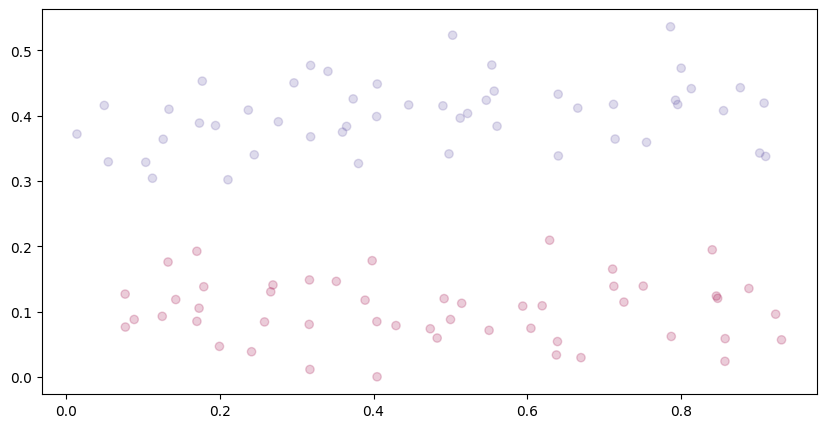

In [29]:
plt.figure(figsize=(10,5))
plt.scatter(X[:, 0], X[:, 1], c=y, alpha=0.2, cmap="Spectral")
plt.show()

In [30]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()

scores = cross_val_score(model, X, y, scoring='accuracy', cv=spltter)
print('Accuracy: %.3f (%.3f)' % (np.mean(scores), np.std(scores)))

Accuracy: 1.000 (0.000)


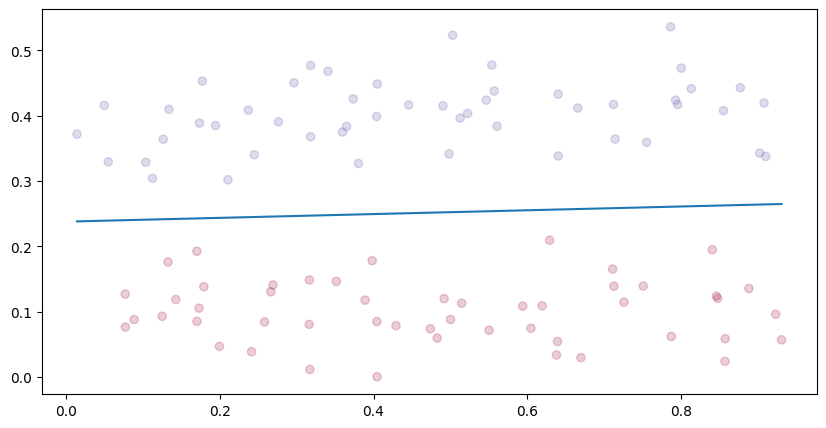

In [31]:
model.fit(X, y)

def plotHyperplan(model, X, y):
  xs = np.array([X[:, 0].min(), X[:, 0].max()])
  vector = model.coef_[0]
  bias = model.intercept_
  ys = (-vector[0] * xs - bias) / vector[1]
  plt.figure(figsize=(10,5))
  plt.scatter(X[:, 0], X[:, 1], c=y, alpha=0.2, cmap="Spectral")
  plt.plot(xs, ys)
  plt.show()

plotHyperplan(model, X, y)

In [32]:
scores = cross_val_score(model, X[:, 1:], y, scoring='accuracy', cv=spltter)
print('Accuracy: %.3f (%.3f)' % (np.mean(scores), np.std(scores)))

Accuracy: 1.000 (0.000)


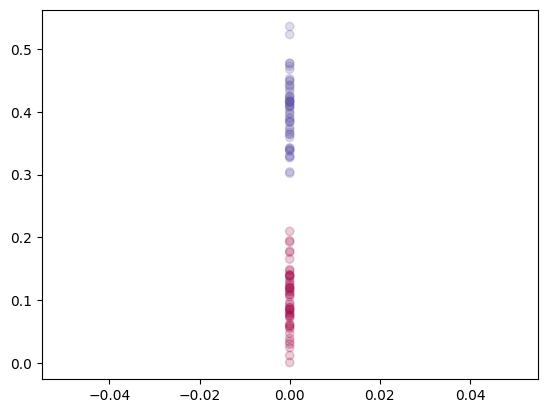

In [36]:
plt.scatter(np.zeros_like(X[:,0]), X[:,1], c=y, alpha=0.2, cmap="Spectral")
plt.show()

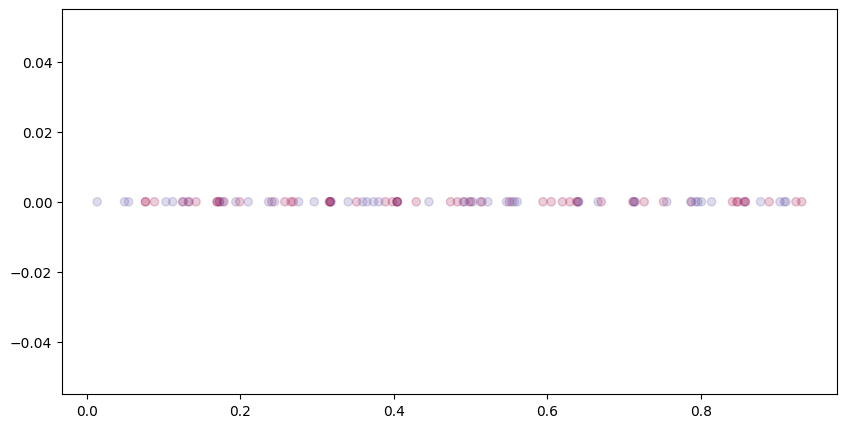

In [39]:
plt.figure(figsize=(10,5))
plt.scatter(X[:,0], np.zeros_like(X[:,1]), c=y, alpha=0.2, cmap="Spectral")
plt.show()

In [40]:
pca = PCA(n_components=1)
pca.fit(X)
X_pca = pca.transform(X)
print(X_pca.shape)

(100, 1)


In [41]:
scores = cross_val_score(model, X_pca, y, scoring='accuracy', cv=spltter)
print('Accuracy: %.3f (%.3f)' % (np.mean(scores), np.std(scores)))

Accuracy: 0.460 (0.069)


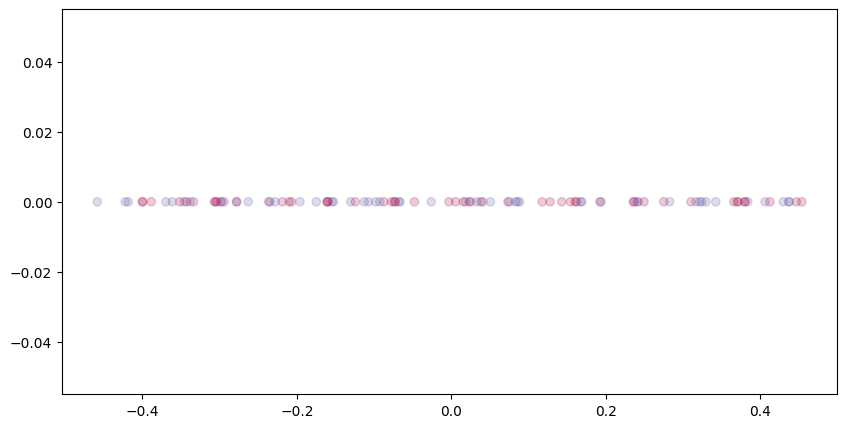

In [42]:
plt.figure(figsize=(10,5))
plt.scatter(X_pca, np.zeros_like(X_pca), c=y, alpha=0.2, cmap="Spectral")
plt.show()

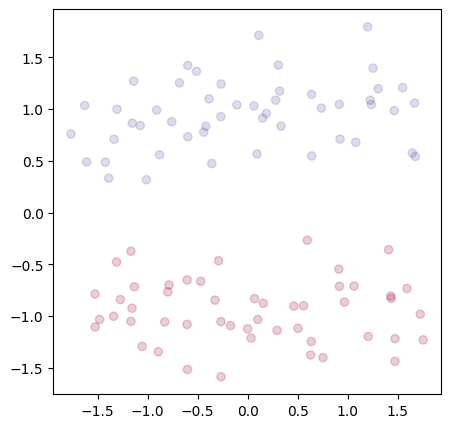

In [43]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_std = scaler.fit_transform(X)
plt.figure(figsize=(5,5))
plt.scatter(X_std[:, 0], X_std[:, 1], c=y, alpha=0.2, cmap="Spectral")
plt.show()

In [46]:
scores = cross_val_score(model, X_std, y, scoring='accuracy', cv=spltter)
print('Accuracy: %.3f (%.3f)' % (np.mean(scores), np.std(scores)))

Accuracy: 1.000 (0.000)


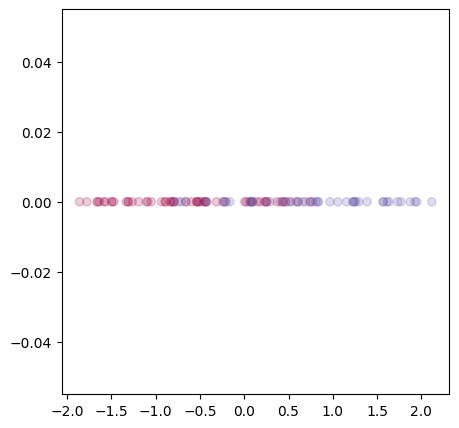

In [44]:
X_std_pca = pca.fit_transform(X_std)
plt.figure(figsize=(5,5))
plt.scatter(X_std_pca, np.zeros_like(X_std_pca), c=y, alpha=0.2, cmap="Spectral")
plt.show()

In [45]:
scores = cross_val_score(model, X_std_pca, y, scoring='accuracy', cv=spltter)
print('Accuracy: %.3f (%.3f)' % (np.mean(scores), np.std(scores)))

Accuracy: 0.753 (0.048)
